<a href="https://colab.research.google.com/github/ganapriyahs/learn_ml_with_me/blob/main/Neural_networks_binary_digits.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Networks (Binary) = Recognizing a handwritten 0 vs 1
#### In this file I walk through how a neural network makes a prediction (**forward propagation**), building it layer by layer in NumPy before touching any framework.

Task: given a picture of a handwritten digit, decide if it is a **0 or a 1**.

A neural network is just logistic regression stacked in layers. Each *neuron* does what I already know: `a = g(w . x + b)`. A *layer* is several neurons looking at the same input; the output of one layer becomes the input of the next.

```
image (64 pixels) -> Layer 1 (25 neurons, sigmoid) -> Layer 2 (15 neurons, sigmoid) -> Layer 3 (1 neuron, sigmoid) -> P(digit is 1)
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## The dataset
The course lab uses 20x20 images (400 pixels). I use the 8x8 digits that ship with scikit-learn (64 pixels, no download), keeping only the 0s and 1s.

X: (360, 64) | y: (360,) | zeros: 178 ones: 182


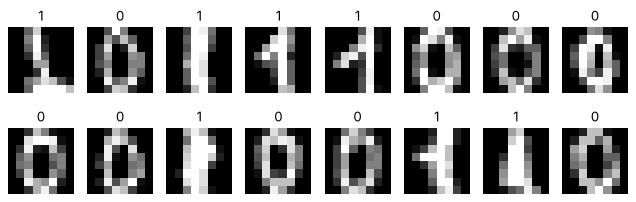

In [2]:
from sklearn.datasets import load_digits
digits = load_digits()
mask = np.isin(digits.target, [0, 1])
X = digits.data[mask] / 16.0                       # pixel values 0..16 -> 0..1
y = digits.target[mask]
print("X:", X.shape, "| y:", y.shape, "| zeros:", (y == 0).sum(), "ones:", (y == 1).sum())

fig, axes = plt.subplots(2, 8, figsize=(10, 3))
rng = np.random.default_rng(0)
for ax, i in zip(axes.ravel(), rng.choice(len(X), 16, replace=False)):
    ax.imshow(X[i].reshape(8, 8), cmap="gray"); ax.set_title(int(y[i])); ax.axis("off")
plt.show()

## Train the weights
The point of this notebook is forward propagation, so I need weights to propagate with. I train the 64-25-15-1 network using scikit-learn's `MLPClassifier` (it does the backpropagation for me) and then **pull the weights out** to run the forward pass by hand.

In [3]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
mlp = MLPClassifier(hidden_layer_sizes=(25, 15), activation="logistic", max_iter=2000, random_state=1).fit(X_tr, y_tr)
print("sklearn test accuracy:", mlp.score(X_te, y_te))

# weights[l] has shape (inputs_to_layer, neurons_in_layer) - same layout as the course lab
for l, (W, b) in enumerate(zip(mlp.coefs_, mlp.intercepts_), start=1):
    print(f"layer {l}: W{l} {W.shape}, b{l} {b.shape}")

sklearn test accuracy: 1.0
layer 1: W1 (64, 25), b1 (25,)
layer 2: W2 (25, 15), b2 (15,)
layer 3: W3 (15, 1), b3 (1,)


## Forward prop, version 1: one neuron at a time (loops)
A dense layer: for every neuron `j`, compute `z_j = w_j . a_in + b_j` and then `a_j = sigmoid(z_j)`.

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def my_dense(a_in, W, b, g=sigmoid):
    units = W.shape[1]
    a_out = np.zeros(units)
    for j in range(units):
        w = W[:, j]
        z = np.dot(w, a_in) + b[j]
        a_out[j] = g(z)
    return a_out

def my_sequential(x, params):
    a = x
    for W, b in params:
        a = my_dense(a, W, b)
    return a

params = list(zip(mlp.coefs_, mlp.intercepts_))
x0 = X_te[0]
print("true label:", y_te[0], "| my forward prop P(1) =", my_sequential(x0, params)[0].round(4),
      "| sklearn P(1) =", mlp.predict_proba(x0[None, :])[0, 1].round(4))

true label: 1 | my forward prop P(1) = 0.9876 | sklearn P(1) = 0.9876


My hand-written network and scikit-learn agree - so I understand exactly what a "layer" computes.

## Forward prop, version 2: vectorized
Loops are slow. A whole layer is one matrix multiplication: `A_out = g(A_in @ W + b)`. NumPy **broadcasting** adds the bias vector `b` (shape `(units,)`) to every row of the matrix `A_in @ W` (shape `(examples, units)`) automatically, and the same code now handles *all* examples at once.

In [5]:
def my_dense_v(A_in, W, b, g=sigmoid):
    return g(A_in @ W + b)

def my_sequential_v(X, params):
    A = X
    for W, b in params:
        A = my_dense_v(A, W, b)
    return A

probs = my_sequential_v(X_te, params).ravel()
print("max difference vs sklearn on all test images:", np.abs(probs - mlp.predict_proba(X_te)[:, 1]).max())

max difference vs sklearn on all test images: 3.469446951953614e-18


A tiny demo of broadcasting, because it confused me at first:

In [6]:
M = np.array([[1, 2, 3], [4, 5, 6]])          # shape (2, 3)
b = np.array([10, 20, 30])                    # shape (3,)
print(M + b)                                  # b is added to EACH ROW
print("column vector (2,1) + row (3,) ->\n", np.array([[100], [200]]) + b)     # stretches both -> (2, 3)

[[11 22 33]
 [14 25 36]]
column vector (2,1) + row (3,) ->
 [[110 120 130]
 [210 220 230]]


## Making predictions
The output is a probability; I threshold at 0.5.

test accuracy (my forward prop): 1.0


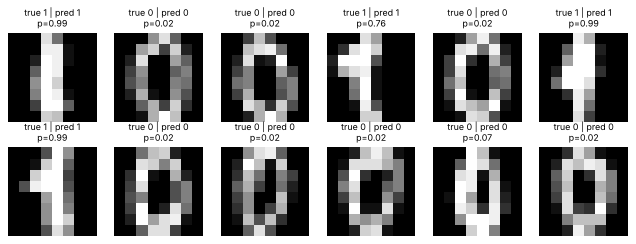

In [7]:
pred = (probs >= 0.5).astype(int)
print("test accuracy (my forward prop):", (pred == y_te).mean())

fig, axes = plt.subplots(2, 6, figsize=(10, 3.4))
for ax, i in zip(axes.ravel(), range(12)):
    ax.imshow(X_te[i].reshape(8, 8), cmap="gray"); ax.axis("off")
    ax.set_title(f"true {y_te[i]} | pred {pred[i]}\np={probs[i]:.2f}", fontsize=8)
plt.show()

## What did the first layer learn?
Each of the 25 neurons in layer 1 has 64 weights - one per pixel. Drawn as an 8x8 picture, a neuron's weights show the pixel pattern it responds to.

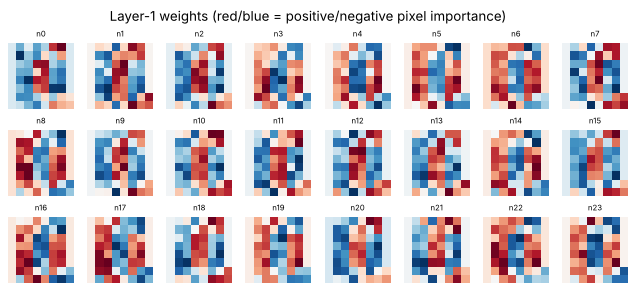

In [8]:
W1 = mlp.coefs_[0]
fig, axes = plt.subplots(3, 8, figsize=(10, 4))
for j, ax in enumerate(axes.ravel()):
    if j < W1.shape[1]:
        ax.imshow(W1[:, j].reshape(8, 8), cmap="RdBu"); ax.set_title(f"n{j}", fontsize=7)
    ax.axis("off")
plt.suptitle("Layer-1 weights (red/blue = positive/negative pixel importance)"); plt.show()

## The same network in TensorFlow / Keras
This is what the course lab does. `Sequential` + `Dense` hides the loops and matrix multiplications I just wrote, and `fit` does the backpropagation. **I could not run this cell where I prepared this notebook (no TensorFlow there) - run it in Colab.**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    tf.keras.Input(shape=(64,)),
    Dense(25, activation="sigmoid", name="layer1"),
    Dense(15, activation="sigmoid", name="layer2"),
    Dense(1,  activation="sigmoid", name="layer3"),
])
model.summary()
model.compile(loss=tf.keras.losses.BinaryCrossentropy(), optimizer=tf.keras.optimizers.Adam(0.01))
model.fit(X_tr, y_tr, epochs=20, verbose=0)
print("Keras test accuracy:", ((model.predict(X_te).ravel() >= 0.5) == y_te).mean())

# the weights have the same shapes as my NumPy version
W1k, b1k = model.get_layer("layer1").get_weights()
print(W1k.shape, b1k.shape)

## Drawbacks / things to remember
- 0 vs 1 is the *easiest* digit problem; the shapes are very different. Multi-digit classification (next notebook) is harder.
- A fully connected network ignores that pixels have neighbours: it treats the image as a flat list of 64 numbers. Convolutional networks use the 2-D structure and do much better on images.
- I trained for many iterations on a tiny dataset - there is a risk of overfitting. I must always report accuracy on data the model did **not** train on.
- Sigmoid in hidden layers is the old-school choice; ReLU (next notebook) trains faster and avoids vanishing gradients.
- A neural network is a black box: the first-layer pictures are as close to an explanation as I get.